# Day 2 lecture: Visualising and communicating data

<p class="lead">
Periods 1 to 4 of Day 2. How to choose a chart for the question being asked, why the eye reads some charts more accurately than others, how colour helps or excludes readers, how honest data can be drawn dishonestly and how to rebuild it, and how to turn a finding into a message, a KPI, a dashboard and a marketing decision.
</p>

Run each code cell with **Shift + Enter**, in order. The examples use the **penguins** and **mpg** data and synthetic data made inside the notebook. Lab 2 uses Tableau's Superstore data and Assignment 1 uses the restaurant tips data; this lecture uses **neither**, so that you practise the ideas here and apply them yourself in the graded work.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder; everything loads from `data/`.
- **Route A (Try JupyterLab):** upload this notebook, `data/penguins.csv` and `data/mpg.csv`, run `%pip install seaborn` in a first cell, and remove `data/` from the two file paths in the setup cell.

---

## What you will be able to do

1. Choose a chart from the **shape of the question** (rank, change, distribution, relationship, part-to-whole, deviation) and defend it against an alternative.
2. Explain why **position and length** beat angle, area and colour, and use **pre-attentive attributes** and **Gestalt** grouping to direct the reader's eye.
3. Remove clutter (**data-ink**) and choose **colour** that is meaningful and readable by colour-blind readers.
4. Spot six common **misleading charts** and rebuild each one honestly.
5. Write a **big idea**, structure a short report as **situation, complication, resolution**, and title charts with the message, not the topic.
6. Design a **KPI** correctly, including the difference between a **ratio of sums** and a **mean of ratios**, and lay out a **dashboard**.
7. Calculate and interpret the core **marketing metrics**: funnel conversion, CTR, CPC, CPA, ROAS, CLV, and explain the limits of **attribution**.

| Part | Topic | Period |
|---|---|---|
| 1 | Choosing a chart for the question | P1 |
| 2 | Perception: encodings, pre-attentive attributes, Gestalt, data-ink | P1–P2 |
| 3 | Colour and accessibility | P2 |
| 4 | Misleading charts and their rebuilds | P2 |
| 5 | Communicating results: audience, big idea, structure, titles, annotation | P3 |
| 6 | KPIs and dashboards | P3 |
| 7 | Marketing analytics | P4 |
| 8 | Two real cases | P4 |
| 9 | Practice, quiz and summary | Self-study |

> **Reading**
>
> Read Chapter 2 of the course reading packet for the four question shapes and their charts, why position and length are read more accurately than colour and area, dual encoding, and leading with the finding. Its summaries of Gordon's Chapter 5 (*Communicating Analytical Results*) and Chapter 6 (*Marketing Analytics*) frame Parts 5 to 7. This lecture adds perception research, colour and accessibility, misleading charts, KPI arithmetic and the marketing metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

penguins = pd.read_csv("data/penguins.csv").dropna()   # Route A: "penguins.csv"
cars = pd.read_csv("data/mpg.csv")                       # Route A: "mpg.csv"

# One colour-blind-safe palette (Okabe and Ito) and a neutral grey, used all day
OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7", "black": "#000000"}
GREY = "#B0B0B0"

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
print("penguins:", penguins.shape, " cars:", cars.shape)

penguins: (333, 7)  cars: (398, 9)


---

## Part 1: Choosing a chart for the question

A chart is an answer to a question. The most common chart mistake is not ugliness but a mismatch: a pie chart asked to show change over time, or a line drawn through categories that have no order. So start with the **shape of the question**, then pick the form.

| Question shape | Typical words | First choice | Good alternatives | Avoid |
|---|---|---|---|---|
| **Rank or compare** categories | "which is biggest", "top 10" | Bar chart, **sorted**, often horizontal | Dot plot, lollipop | Unsorted bars, pie with many slices |
| **Change over time** | "trend", "since", "per month" | Line chart | Column chart for few periods, area for totals | Pie per year, unequal time gaps |
| **Distribution** of one number | "typical", "spread", "outliers" | Histogram, box plot | Violin, strip (dots), density | A bar of the mean alone |
| **Relationship** between two numbers | "does X go with Y" | Scatter plot | Hexbin for many points, bubble for a third number | Two lines on two axes |
| **Part-to-whole** | "share", "mix", "of the total" | Sorted bar of shares, or one stacked bar | Pie with **2–3** slices, treemap, waffle | Pie with many similar slices, 3-D pie |
| **Deviation** from a reference | "vs target", "above or below" | Diverging bar around zero | Bullet chart, line with a target line | Separate bars for actual and target |
| **Geography** | "where", "by region" | Filled (choropleth) map of a **rate** | Symbol map of totals, sorted bar | A filled map of raw totals |
| **Flow or process** | "where do we lose people" | Funnel (stage bars) | Sankey | Pie of stages |

Two tests before you draw anything:

1. **Write the question as a sentence** ending in a question mark. If you cannot, you are not ready to chart.
2. **Say what the reader should compare.** Bars next to each other? A line against its own past? A point against a target? The chart should put those things side by side, on the same scale.

### Example 1: rank, with sorting

*Which manufacturers have the most models in the mpg data?* The manufacturer is the first word of each car's name.

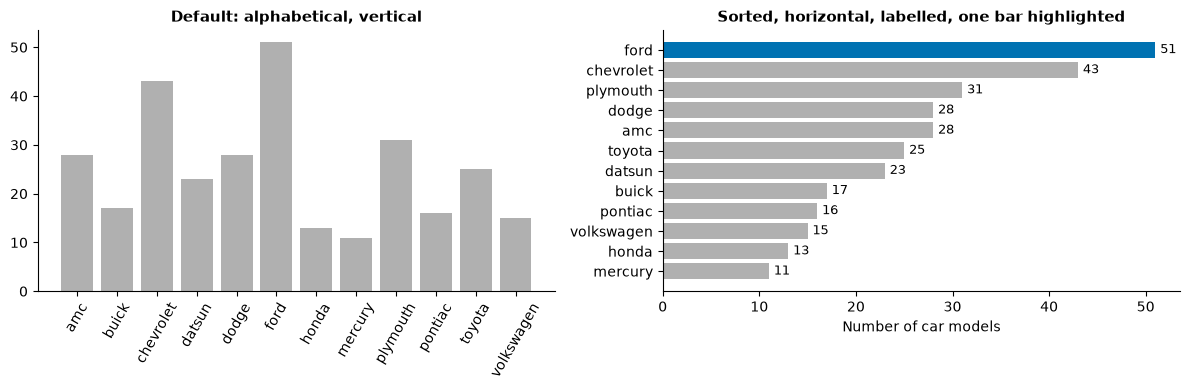

In [2]:
cars["maker"] = cars["name"].str.split().str[0]
counts = cars["maker"].value_counts().head(12)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
alpha_order = counts.sort_index()
axes[0].bar(alpha_order.index, alpha_order.values, color=GREY)
axes[0].set_title("Default: alphabetical, vertical")
axes[0].tick_params(axis="x", rotation=60)

ranked = counts.sort_values()
axes[1].barh(ranked.index, ranked.values, color=GREY)
axes[1].barh(ranked.index[-1], ranked.values[-1], color=OI["blue"])
for y, v in enumerate(ranked.values):
    axes[1].text(v + 0.5, y, str(v), va="center", fontsize=9)
axes[1].set_title("Sorted, horizontal, labelled, one bar highlighted")
axes[1].set_xlabel("Number of car models")
plt.tight_layout()
plt.show()

Both charts hold the same twelve numbers. On the left, the reader must hunt for the longest bar and tilt their head to read the names. On the right, **rank is the order**, names read horizontally, and the labels make the gridlines unnecessary.

> **Look closer.** Scroll through `cars["maker"].value_counts()`. You will find spellings such as `chevy` and `chevroelt` next to `chevrolet`, and `vw` next to `volkswagen`. A chart of counts is only as good as the category labels: data quality (Day 1) comes before chart design.

### Example 2: change over time

*How did fuel economy change across model years, by region of origin?* A line chart, because the x-axis is ordered time and the eye reads slopes.

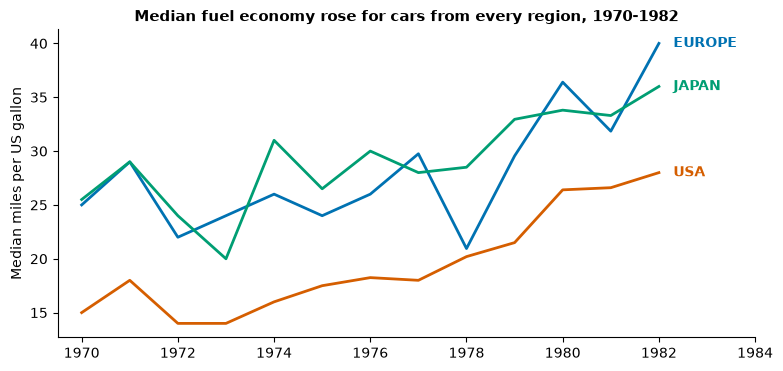

In [3]:
trend = cars.groupby(["model_year", "origin"])["mpg"].median().unstack()
colours = {"usa": OI["vermillion"], "europe": OI["blue"], "japan": OI["green"]}

fig, ax = plt.subplots(figsize=(9, 4))
for region in trend.columns:
    ax.plot(1900 + trend.index, trend[region], color=colours[region], lw=2)
    ax.text(1900 + trend.index[-1] + 0.3, trend[region].iloc[-1], region.upper(),
            color=colours[region], va="center", fontweight="bold")
ax.set_title("Median fuel economy rose for cars from every region, 1970-1982")
ax.set_ylabel("Median miles per US gallon")
ax.set_xlim(1969.5, 1984)
plt.show()

Notice three choices: the **title states the finding**; each line is **labelled directly** at its end, so there is no legend to decode; and the colours come from a colour-blind-safe palette. The y-axis does **not** start at zero: for a line chart that is acceptable, because the eye reads **position and slope**, not length. (Bars are different; see Part 4.)

> **Predict, then run.** Would a pie chart per year show the same story? Try to picture thirteen pies side by side. What could a reader compare, and what could they not?

### Example 3: distribution, and why a bar of the mean is not enough

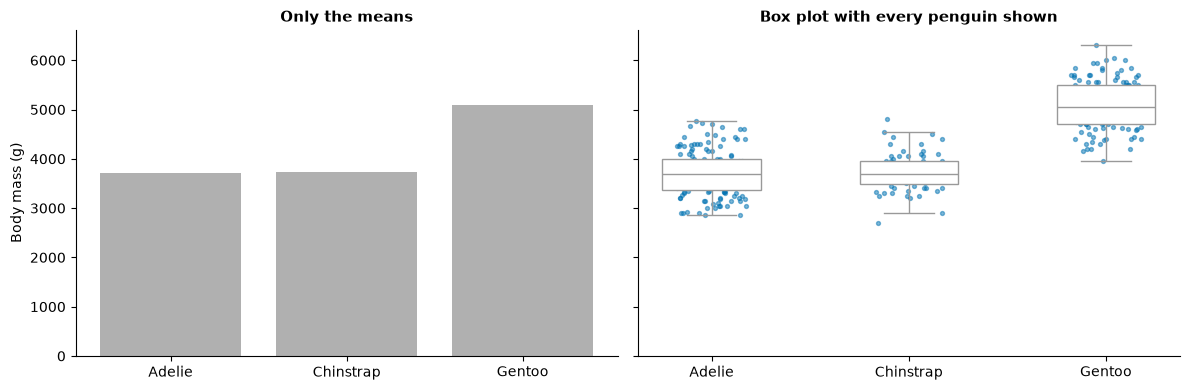

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
means = penguins.groupby("species")["body_mass_g"].mean()
axes[0].bar(means.index, means.values, color=GREY)
axes[0].set_title("Only the means")
axes[0].set_ylabel("Body mass (g)")

order = ["Adelie", "Chinstrap", "Gentoo"]
sns.boxplot(data=penguins, x="species", y="body_mass_g", order=order, color="white",
            width=0.5, showfliers=False, ax=axes[1])
rng = np.random.default_rng(2)
for i, sp in enumerate(order):
    vals = penguins.loc[penguins["species"] == sp, "body_mass_g"]
    axes[1].scatter(i + rng.uniform(-0.18, 0.18, len(vals)), vals, s=8, alpha=0.5, color=OI["blue"])
axes[1].set_title("Box plot with every penguin shown")
axes[1].set_xlabel("")
axes[0].set_xlabel("")
plt.tight_layout()
plt.show()

The bar chart says "Gentoo are heavier". The box-and-dots chart says how much heavier, how much the groups **overlap**, and how many birds stand behind each box. If a decision depends on individuals (which penguin, which customer, which order), show the distribution, not just the average.

**Reading a box plot** (you will need this for Assignment 1): the line inside the box is the **median**; the box spans the middle half of the data, from the first quartile (Q1) to the third (Q3), so its height is the **interquartile range (IQR)**; the whiskers reach the furthest points within 1.5 × IQR of the box; points beyond the whiskers are drawn separately as **outliers**. An outlier is unusual, not necessarily wrong.

### Example 4: relationship

*Do penguins with longer flippers weigh more?* Two numbers per individual: a scatter plot.

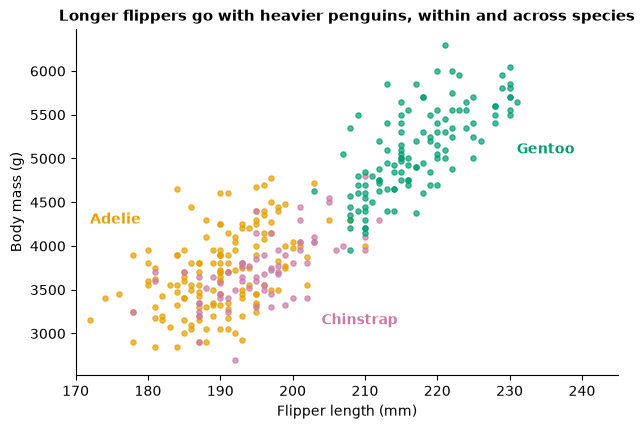

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sp_col = {"Adelie": OI["orange"], "Chinstrap": OI["purple"], "Gentoo": OI["green"]}
for sp, grp in penguins.groupby("species"):
    ax.scatter(grp["flipper_length_mm"], grp["body_mass_g"], s=14, alpha=0.7, color=sp_col[sp])
label_at = {"Adelie": (172, 4300), "Chinstrap": (204, 3150), "Gentoo": (231, 5100)}
for sp, (lx, ly) in label_at.items():
    ax.text(lx, ly, sp, color=sp_col[sp], fontweight="bold", va="center")
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Body mass (g)")
ax.set_title("Longer flippers go with heavier penguins, within and across species")
ax.set_xlim(170, 245)
plt.show()

### Example 5: part-to-whole, the pie problem

Five brands share a market. **Predict, then run:** before you look at the labels, rank the five slices of the pie from largest to smallest.

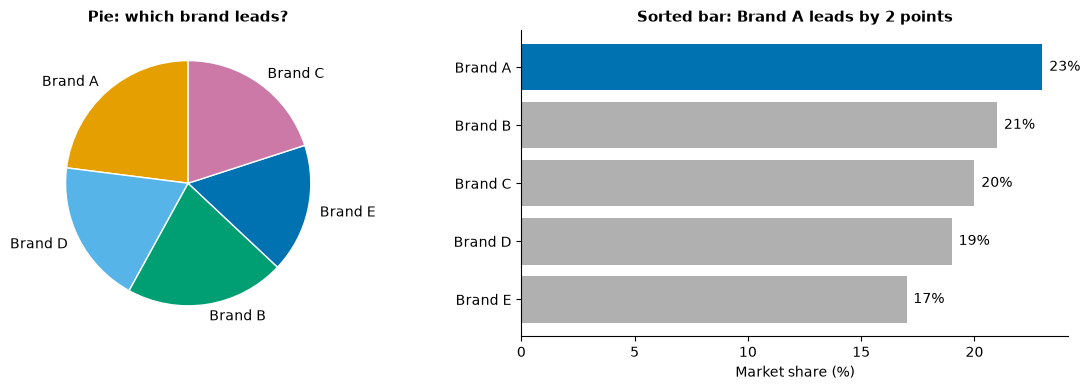

In [6]:
shares = pd.Series({"Brand A": 23, "Brand B": 21, "Brand C": 20, "Brand D": 19, "Brand E": 17})
shuffled = shares.sample(frac=1, random_state=4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].pie(shuffled.values, labels=shuffled.index, startangle=90,
            colors=[OI[c] for c in ["orange", "sky", "green", "blue", "purple"]],
            wedgeprops={"edgecolor": "white"})
axes[0].set_title("Pie: which brand leads?")

s = shares.sort_values()
axes[1].barh(s.index, s.values, color=GREY)
axes[1].barh(s.index[-1], s.values[-1], color=OI["blue"])
for y, v in enumerate(s.values):
    axes[1].text(v + 0.3, y, f"{v}%", va="center")
axes[1].set_xlabel("Market share (%)")
axes[1].set_title("Sorted bar: Brand A leads by 2 points")
plt.tight_layout()
plt.show()

When shares are similar, angles are almost impossible to rank. The bar chart turns the same comparison into **lengths on a common baseline**, which the eye ranks easily. Pies are acceptable when there are two or three parts and the message is roughly "about a quarter" or "most".

### Example 6: deviation from a target

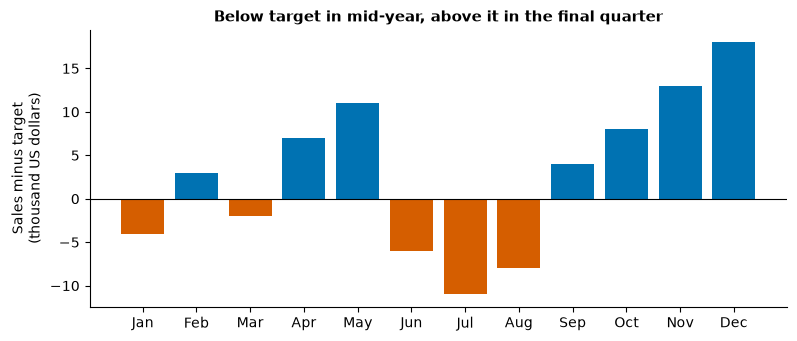

In [7]:
months = pd.period_range("2025-01", periods=12, freq="M").strftime("%b")
target = 100
actual = np.array([96, 103, 98, 107, 111, 94, 89, 92, 104, 108, 113, 118])
gap = actual - target

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(months, gap, color=[OI["blue"] if g >= 0 else OI["vermillion"] for g in gap])
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Sales minus target\n(thousand US dollars)")
ax.set_title("Below target in mid-year, above it in the final quarter")
plt.show()

Plotting **actual minus target** puts the comparison the manager cares about on one axis with zero as the reference. Two colours plus position above or below the line mean the meaning survives in black and white.

### Misconceptions about chart choice

| Misconception | Better view |
|---|---|
| "The chart that looks most impressive is best." | The best chart makes the intended comparison easiest. Impressive often means harder to read. |
| "Every chart needs a legend." | Direct labels are usually faster; a legend forces the eye to travel back and forth. |
| "Lines and bars are interchangeable." | Lines imply continuity and order; use them for time or ordered values, not unordered categories. |
| "A pie is the chart for shares." | Only for two or three parts. Otherwise a sorted bar of percentages is clearer. |
| "Show all the data, always." | Show the data the decision needs, in the form the reader needs; keep the rest available. |

---

## Part 2: Perception

### Encodings and how accurately we read them

A chart **encodes** each number as a visual property: a position, a length, an angle, an area, a shade. In experiments where people estimated ratios from charts, Cleveland and McGill (1984) found a consistent ranking of how accurately each encoding is read:

| Most accurate | | | | Least accurate |
|---|---|---|---|---|
| Position on a common scale | Position on separate, aligned scales | Length, direction, angle | Area | Volume, curvature, shading (colour saturation) |

Colour **hue** is not in their ranking; later work by Mackinlay (1986) ranks hue low for quantities but high for telling categories apart. The practical rule: **put the most important comparison on position or length**; use colour and area for secondary information or rough groups. A second finding from perception research (Stevens' power law) explains why bubbles mislead: people tend to **underestimate** differences in area, so a circle with twice the area looks less than twice as big.

> **Predict, then run.** The next cell shows the same two numbers, A and B, four ways. In each panel, estimate how many times bigger A is than B. Write down your four estimates before reading the answer printed below the figure.

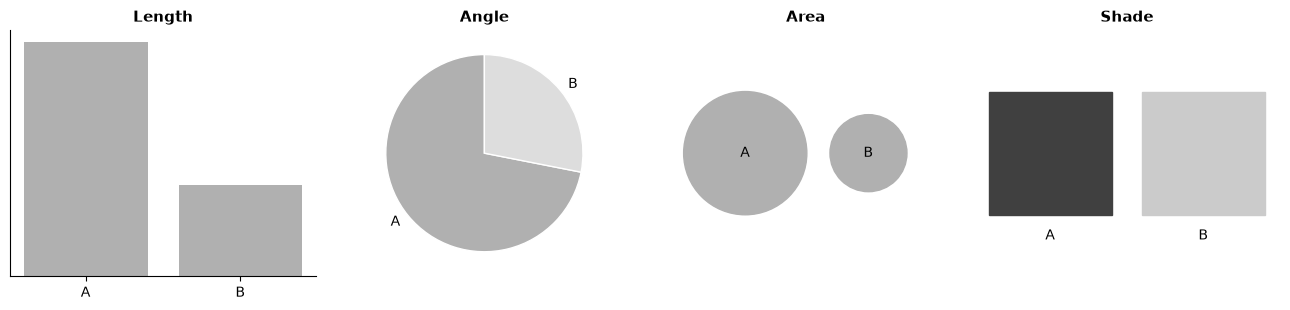

Answer: A is 2.56 times B in every panel.


In [8]:
A, B = 64, 25
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))

axes[0].bar(["A", "B"], [A, B], color=GREY)
axes[0].set_title("Length")
axes[0].set_yticks([])

axes[1].pie([A, B], labels=["A", "B"], colors=[GREY, "#DDDDDD"], startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title("Angle")

for x, v, lab in [(0.28, A, "A"), (0.78, B, "B")]:
    r = np.sqrt(v) / 32
    axes[2].add_patch(plt.Circle((x, 0.5), r, color=GREY))
    axes[2].text(x, 0.5, lab, ha="center", va="center")
axes[2].set_xlim(0, 1.05); axes[2].set_ylim(0, 1); axes[2].set_aspect("equal"); axes[2].axis("off")
axes[2].set_title("Area")

cmap = plt.get_cmap("Greys")
for x, v, lab in [(0.25, A, "A"), (0.75, B, "B")]:
    axes[3].add_patch(plt.Rectangle((x - 0.2, 0.25), 0.4, 0.5, color=cmap(v / 80)))
    axes[3].text(x, 0.15, lab, ha="center")
axes[3].set_xlim(0, 1); axes[3].set_ylim(0, 1); axes[3].axis("off")
axes[3].set_title("Shade")
plt.tight_layout()
plt.show()
print(f"Answer: A is {A / B:.2f} times B in every panel.")

Most people estimate the bars well, the pie roughly, and the circles and shades badly (usually too low for the circles). Nothing in the data changed; only the encoding did.

### Pre-attentive attributes: what the eye sees before it reads

Some visual differences are picked up in a fraction of a second, before any conscious search. These **pre-attentive attributes** include colour hue, intensity, size, orientation, shape, enclosure and added marks. You can use them to send the reader's eye straight to the point, or, by using too many at once, to send it everywhere.

> **Predict, then run.** In each panel there is one odd point. Which panel will take you longest to find it in?

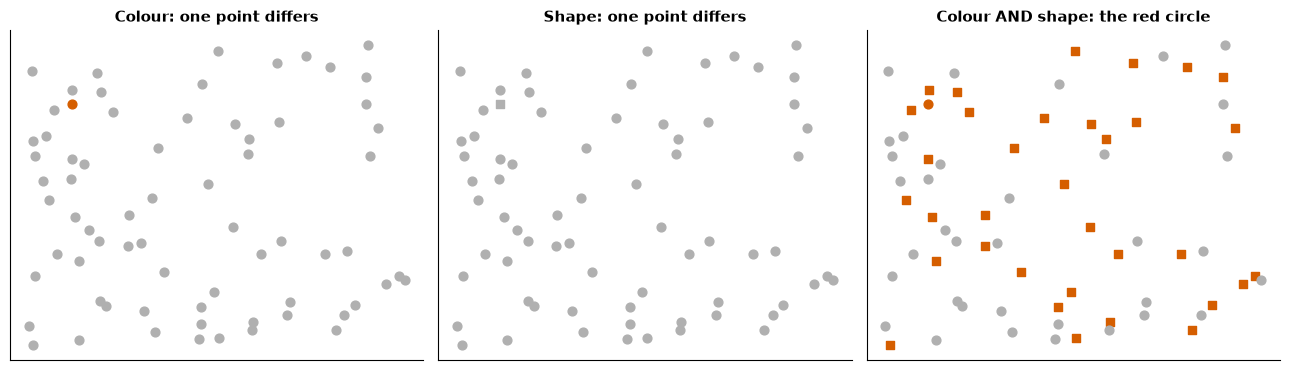

In [9]:
rng = np.random.default_rng(11)
n = 70
x, y = rng.uniform(0, 1, n), rng.uniform(0, 1, n)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

axes[0].scatter(x[1:], y[1:], color=GREY, s=40)
axes[0].scatter(x[0], y[0], color=OI["vermillion"], s=40)
axes[0].set_title("Colour: one point differs")

axes[1].scatter(x[1:], y[1:], color=GREY, s=40, marker="o")
axes[1].scatter(x[0], y[0], color=GREY, s=40, marker="s")
axes[1].set_title("Shape: one point differs")

half = n // 2
axes[2].scatter(x[1:half], y[1:half], color=OI["vermillion"], s=40, marker="s")
axes[2].scatter(x[half:], y[half:], color=GREY, s=40, marker="o")
axes[2].scatter(x[0], y[0], color=OI["vermillion"], s=40, marker="o")
axes[2].set_title("Colour AND shape: the red circle")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

The red point on the left "pops out". The square in the middle takes longer: shape is a weaker pre-attentive cue than colour. The right panel is slowest because the target differs only in a **combination** of colour and shape, which the eye has to search for point by point. Lesson for dashboards: **one** highlight colour against grey is powerful; five bright colours cancel each other out.

### Gestalt principles: how the eye groups things

Gestalt psychology describes how we see marks as groups. Four principles matter most for charts:

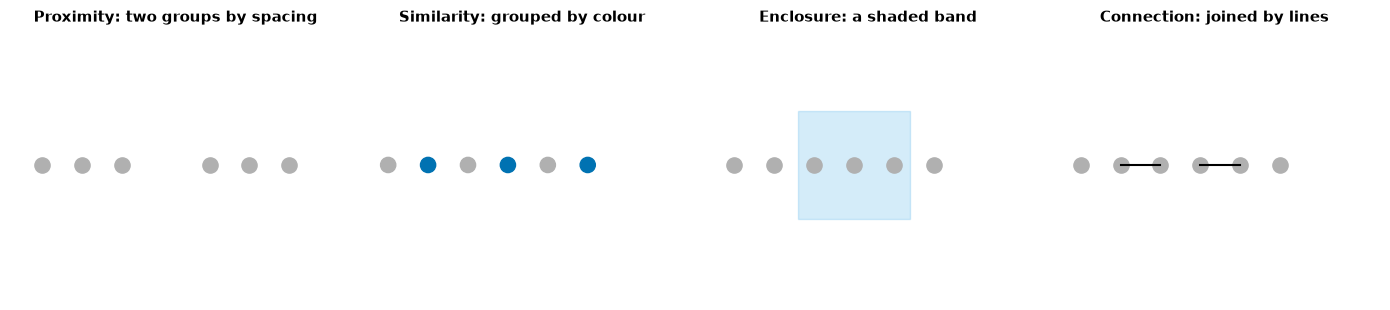

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
xs = np.arange(6)

axes[0].scatter(np.r_[xs[:3], xs[3:] + 1.2], np.zeros(6), s=120, color=GREY)
axes[0].set_title("Proximity: two groups by spacing")

axes[1].scatter(xs, np.zeros(6), s=120, color=[OI["blue"] if i % 2 else GREY for i in xs])
axes[1].set_title("Similarity: grouped by colour")

axes[2].add_patch(plt.Rectangle((1.6, -0.4), 2.8, 0.8, color=OI["sky"], alpha=0.25))
axes[2].scatter(xs, np.zeros(6), s=120, color=GREY)
axes[2].set_title("Enclosure: a shaded band")

axes[3].scatter(xs, np.zeros(6), s=120, color=GREY)
axes[3].plot([1, 2], [0, 0], color="black"); axes[3].plot([3, 4], [0, 0], color="black")
axes[3].set_title("Connection: joined by lines")
for ax in axes:
    ax.set_ylim(-1, 1); ax.set_xlim(-0.8, 7.5); ax.axis("off")
plt.tight_layout()
plt.show()

| Principle | What the eye does | Use it in a chart |
|---|---|---|
| **Proximity** | Treats close marks as a group | Put bars that should be compared next to each other; leave gaps between groups |
| **Similarity** | Treats same-coloured or same-shaped marks as a group | Give one series one colour everywhere on the dashboard |
| **Enclosure** | Treats marks inside a boundary as a group | Shade a period (a promotion, a recession) or box related KPIs together |
| **Connection** | Treats joined marks as a sequence | Lines connect time points; do not connect unordered categories |
| Continuity, closure | Follows smooth paths, completes shapes | Light gridlines are enough; the eye completes the alignment |

### Data-ink: remove what does not carry data

Edward Tufte's **data-ink ratio** is the share of a chart's ink that shows data. Heavy borders, dark gridlines, shadows, 3-D effects, repeated labels and decorative images ("chart junk") use ink without adding information and compete with the data for attention. The aim is not minimalism for its own sake but **attention on the data**.

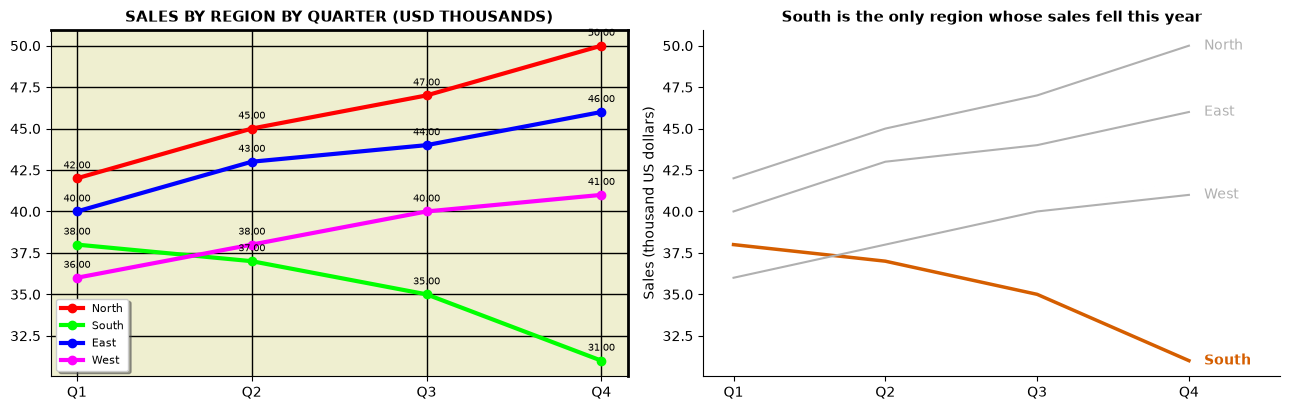

In [11]:
quarters = ["Q1", "Q2", "Q3", "Q4"]
regions = {"North": [42, 45, 47, 50], "South": [38, 37, 35, 31], "East": [40, 43, 44, 46], "West": [36, 38, 40, 41]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bright = ["red", "lime", "blue", "magenta"]
for (name, vals), col in zip(regions.items(), bright):
    ax.plot(quarters, vals, marker="o", lw=3, color=col, label=name)
    for q, v in zip(quarters, vals):
        ax.text(q, v + 0.6, f"{v:.2f}", fontsize=7, ha="center")
ax.grid(True, color="black", lw=1)
for side in ["top", "right"]:
    ax.spines[side].set_visible(True); ax.spines[side].set_linewidth(2)
ax.set_facecolor("#EFEFD0")
ax.legend(loc="lower left", fontsize=8, frameon=True, shadow=True)
ax.set_title("SALES BY REGION BY QUARTER (USD THOUSANDS)")

ax = axes[1]
for name, vals in regions.items():
    col = OI["vermillion"] if name == "South" else GREY
    ax.plot(quarters, vals, lw=2.5 if name == "South" else 1.5, color=col)
    ax.text(3.1, vals[-1], name, color=col, va="center", fontweight="bold" if name == "South" else None)
ax.set_title("South is the only region whose sales fell this year")
ax.set_ylabel("Sales (thousand US dollars)")
ax.set_xlim(-0.2, 3.6)
plt.tight_layout()
plt.show()

The left chart is not wrong; it is just loud. The right chart removes the frame, the dark grid, the background, the legend and sixteen over-precise labels, puts one region in colour and three in grey, and says the finding in the title. **Decluttering checklist:** remove borders and backgrounds; lighten or drop gridlines; label directly instead of a legend; round numbers to what the decision needs; one accent colour; no 3-D, shadows or images inside the plot area.

| Misconception | Better view |
|---|---|
| "Maximise data-ink: delete everything." | Keep what helps reading: axis labels with units, a light grid for precise lookups, a source note. |
| "More colours make a chart more informative." | Each extra colour weakens the others. Use grey for context and colour for the point. |

---

## Part 3: Colour and accessibility

### Three kinds of palette

Choose the palette from the **kind of variable**, not from taste:

- **Sequential** (light to dark, one hue): ordered values from low to high, such as sales or population.
- **Diverging** (two hues meeting at a neutral midpoint): values above and below a meaningful centre, such as profit (around zero) or change versus last year. The midpoint must be set at that centre.
- **Categorical** (distinct hues, similar lightness): unordered groups such as regions or brands. Keep to about six; beyond that, group the rest as "Other" or use labels.

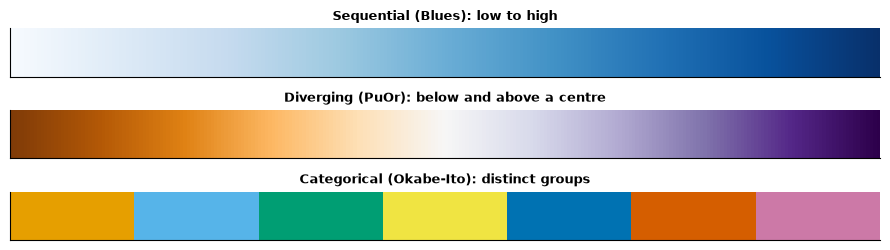

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(9, 2.6))
grad = np.linspace(0, 1, 256)[None, :]
axes[0].imshow(grad, aspect="auto", cmap="Blues"); axes[0].set_title("Sequential (Blues): low to high", fontsize=9)
axes[1].imshow(grad, aspect="auto", cmap="PuOr"); axes[1].set_title("Diverging (PuOr): below and above a centre", fontsize=9)
cat = list(OI.values())[:7]
axes[2].imshow(np.arange(7)[None, :], aspect="auto", cmap=mcolors.ListedColormap(cat))
axes[2].set_title("Categorical (Okabe-Ito): distinct groups", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

### Why the rainbow palette misleads

The classic rainbow ("jet") palette changes **lightness** up and down as it changes hue, so the eye sees bands and edges that are not in the data, and the order of colours is not intuitive. Perceptually uniform palettes such as **viridis** get steadily lighter from one end to the other. The next cell measures the lightness of each palette along its length.

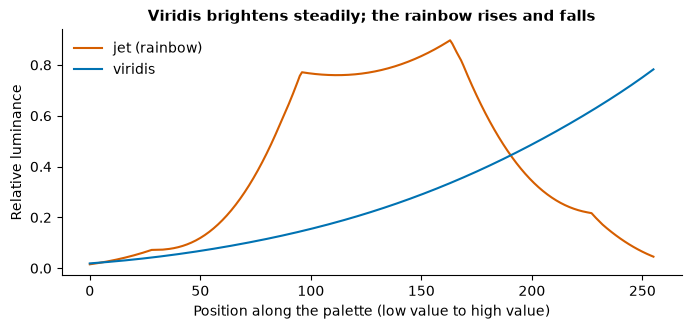

In [13]:
def lightness(cmap_name, n=256):
    """Approximate perceived lightness (relative luminance) along a colormap."""
    rgb = plt.get_cmap(cmap_name)(np.linspace(0, 1, n))[:, :3]
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    return lin @ np.array([0.2126, 0.7152, 0.0722])

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(lightness("jet"), color=OI["vermillion"], label="jet (rainbow)")
ax.plot(lightness("viridis"), color=OI["blue"], label="viridis")
ax.set_xlabel("Position along the palette (low value to high value)")
ax.set_ylabel("Relative luminance")
ax.set_title("Viridis brightens steadily; the rainbow rises and falls")
ax.legend(frameon=False)
plt.show()

### Colour vision deficiency

Roughly 1 in 12 men and 1 in 200 women of Northern European ancestry have some form of colour vision deficiency, most often difficulty telling **red from green**; rates are somewhat lower but still substantial in East Asian populations. In a class of forty, expect at least one or two readers who cannot separate a red–green "bad/good" palette. The next cell simulates deuteranopia (missing green-sensitive cones) using the matrix published by Machado, Oliveira and Fernandes (2009). It is an approximation, but good enough to test a palette.

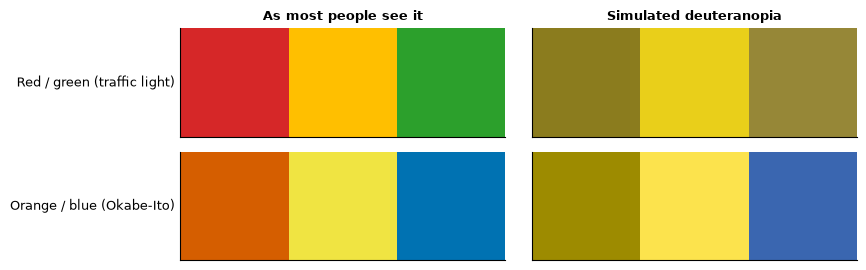

In [14]:
DEUTAN = np.array([[0.367322, 0.860646, -0.227968],
                   [0.280085, 0.672501, 0.047413],
                   [-0.011820, 0.042940, 0.968881]])

def simulate_deutan(hex_colours):
    rgb = np.array([mcolors.to_rgb(h) for h in hex_colours])
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    sim = np.clip(lin @ DEUTAN.T, 0, 1)
    return np.where(sim <= 0.0031308, sim * 12.92, 1.055 * sim ** (1 / 2.4) - 0.055)

palettes = {"Red / green (traffic light)": ["#D62728", "#FFBF00", "#2CA02C"],
            "Orange / blue (Okabe-Ito)": [OI["vermillion"], OI["yellow"], OI["blue"]]}
fig, axes = plt.subplots(2, 2, figsize=(9, 2.8))
for row, (name, pal) in enumerate(palettes.items()):
    axes[row, 0].imshow(np.array([[mcolors.to_rgb(c) for c in pal]]))
    axes[row, 1].imshow(simulate_deutan(pal)[None, :, :])
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
axes[0, 0].set_title("As most people see it", fontsize=9)
axes[0, 1].set_title("Simulated deuteranopia", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In the simulation the red and green of the traffic-light palette collapse into similar brownish tones, while the orange–blue pair stays distinct. This is one reason Tableau's default for a measure such as profit is an **orange–blue diverging** palette rather than red–green.

### Accessibility rules worth keeping

1. **Never rely on colour alone.** Add a label, a sign (+/−), a position above or below a line, or a shape.
2. Use **colour-blind-safe palettes** (Okabe-Ito, viridis, Tableau's Color Blind palette) and check with a simulator.
3. Keep **contrast** high for text: dark text on a light background; the WCAG guideline for normal text is a contrast ratio of at least 4.5:1.
4. Keep colour meanings **consistent** across every chart on a page: if the South is orange in one chart, it is orange in all of them.
5. Make text **large enough** to read when projected or printed, and write a one-sentence **alt text** or caption that states the message for readers who cannot see the chart.

---

## Part 4: Misleading charts and their rebuilds

A chart can be built from correct numbers and still lead a reader to a wrong conclusion. Each example below shows a misleading version (left) and an honest rebuild (right), all on synthetic data.

### 1. The truncated bar axis

Two products' satisfaction scores are 81.2 and 82.9 out of 100.

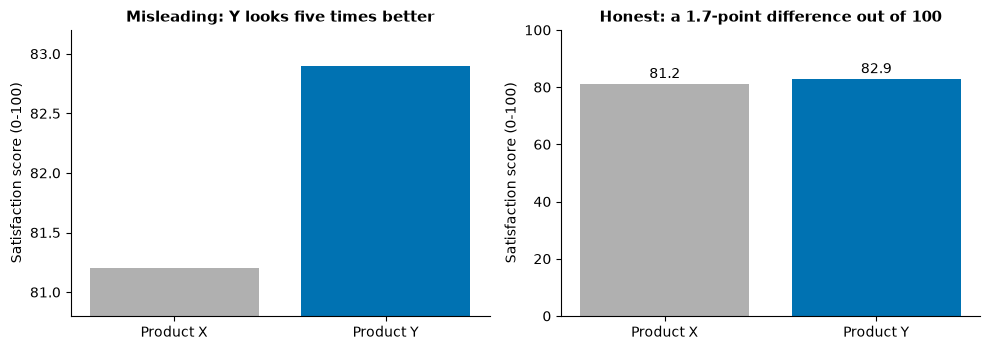

In [15]:
scores = pd.Series({"Product X": 81.2, "Product Y": 82.9})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(scores.index, scores.values, color=[GREY, OI["blue"]])
axes[0].set_ylim(80.8, 83.2)
axes[0].set_title("Misleading: Y looks five times better")
axes[1].bar(scores.index, scores.values, color=[GREY, OI["blue"]])
axes[1].set_ylim(0, 100)
for i, v in enumerate(scores.values):
    axes[1].text(i, v + 2, f"{v}", ha="center")
axes[1].set_title("Honest: a 1.7-point difference out of 100")
for ax in axes:
    ax.set_ylabel("Satisfaction score (0-100)")
plt.tight_layout()
plt.show()

**Rule:** a bar's **length** encodes its value, so bars must start at zero. If the small difference is what matters, show the difference itself (a dot plot, or a bar of "Y minus X") rather than cutting the axis. Line charts and dot plots may start elsewhere, because they encode position.

### 2. Two axes that manufacture a relationship

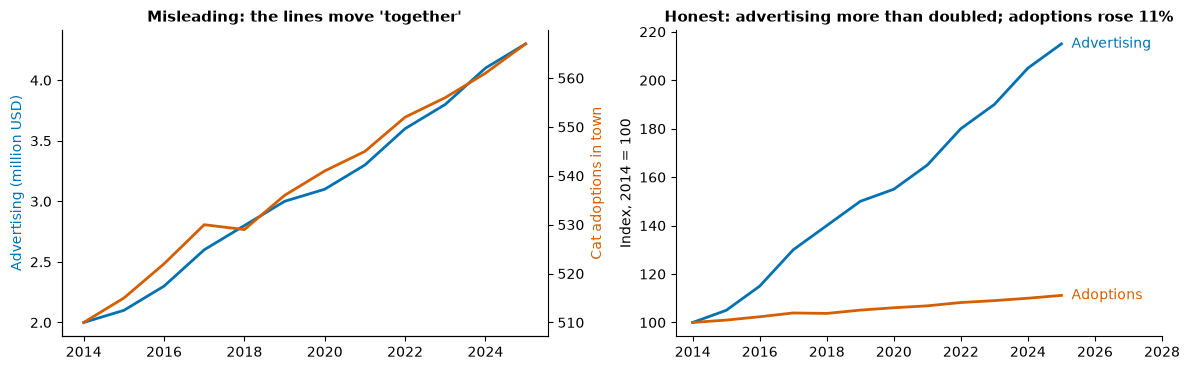

In [16]:
years = np.arange(2014, 2026)
ads = np.array([2.0, 2.1, 2.3, 2.6, 2.8, 3.0, 3.1, 3.3, 3.6, 3.8, 4.1, 4.3])     # million USD
cats = np.array([510, 515, 522, 530, 529, 536, 541, 545, 552, 556, 561, 567])  # cat adoptions

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]; ax2 = ax.twinx()
ax.plot(years, ads, color=OI["blue"], lw=2); ax2.plot(years, cats, color=OI["vermillion"], lw=2)
ax.set_ylabel("Advertising (million USD)", color=OI["blue"])
ax2.set_ylabel("Cat adoptions in town", color=OI["vermillion"])
ax2.spines["right"].set_visible(True)
ax.set_title("Misleading: the lines move 'together'")

ax = axes[1]
ax.plot(years, 100 * ads / ads[0], color=OI["blue"], lw=2)
ax.plot(years, 100 * cats / cats[0], color=OI["vermillion"], lw=2)
ax.text(2025.3, 100 * ads[-1] / ads[0], "Advertising", color=OI["blue"], va="center")
ax.text(2025.3, 100 * cats[-1] / cats[0], "Adoptions", color=OI["vermillion"], va="center")
ax.set_ylabel("Index, 2014 = 100")
ax.set_xlim(2013.5, 2028)
ax.set_title("Honest: advertising more than doubled; adoptions rose 11%")
plt.tight_layout()
plt.show()

With two y-axes, the analyst chooses both scales and can make **any** two rising series overlap. Rebuild by putting both on one **index** scale (each series divided by its starting value), or in two separate panels. And remember Day 1: two series that both trend upwards will correlate whether or not they are related.

### 3. Area that grows with the radius

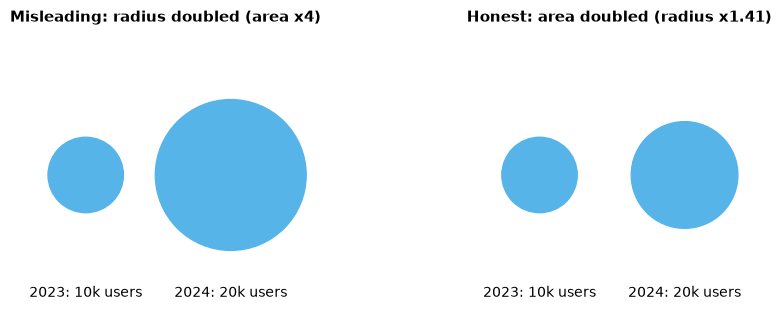

In [17]:
values = pd.Series({"2023": 10, "2024": 20})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, title, scale in [(axes[0], "Misleading: radius doubled (area x4)", "radius"),
                         (axes[1], "Honest: area doubled (radius x1.41)", "area")]:
    for i, (lab, v) in enumerate(values.items()):
        r = 0.13 * (v / 10 if scale == "radius" else np.sqrt(v / 10))
        ax.add_patch(plt.Circle((0.25 + 0.5 * i, 0.5), r, color=OI["sky"]))
        ax.text(0.25 + 0.5 * i, 0.08, f"{lab}: {v}k users", ha="center")
    ax.set_xlim(0, 1.05); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title)
plt.tight_layout()
plt.show()

If a circle's **radius** is scaled by the value, its **area** grows with the square, so a doubling looks like a quadrupling. Scale the area (matplotlib's `s=` in `scatter` and Tableau's Size both scale area), or better, use bars.

### 4. The cherry-picked window

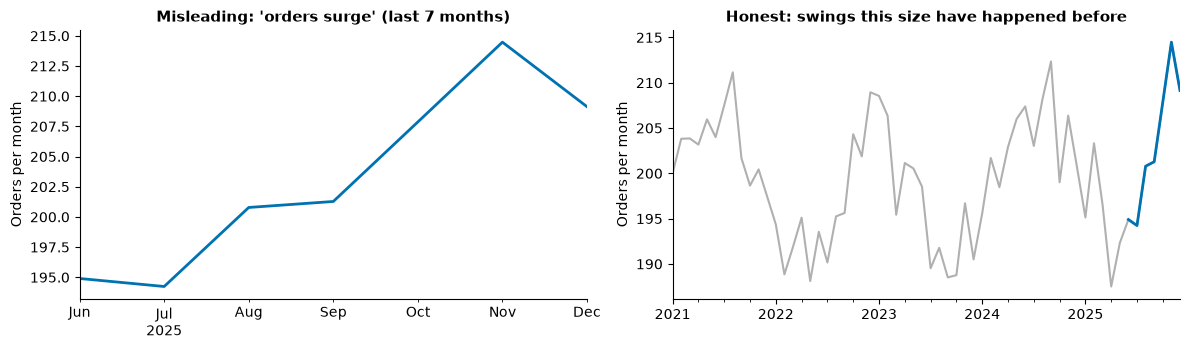

In [18]:
rng = np.random.default_rng(7)
dates = pd.date_range("2021-01-01", periods=60, freq="MS")
series = 200 + 8 * np.sin(np.arange(60) / 3) + rng.normal(0, 4, 60)
series[-7:] = series[-7:] + np.linspace(0, 6, 7)
s = pd.Series(series, index=dates)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
s.iloc[-7:].plot(ax=axes[0], color=OI["blue"], lw=2)
axes[0].set_title("Misleading: 'orders surge' (last 7 months)")
s.plot(ax=axes[1], color=GREY, lw=1.5)
s.iloc[-7:].plot(ax=axes[1], color=OI["blue"], lw=2)
axes[1].set_title("Honest: swings this size have happened before")
for ax in axes:
    ax.set_ylabel("Orders per month"); ax.set_xlabel("")
plt.tight_layout()
plt.show()

A short window hides the normal ups and downs. Ask: **why does the chart start where it starts?** Show enough history to see the usual variation, and mark the period you are talking about rather than cropping to it.

### 5. Totals where rates are needed

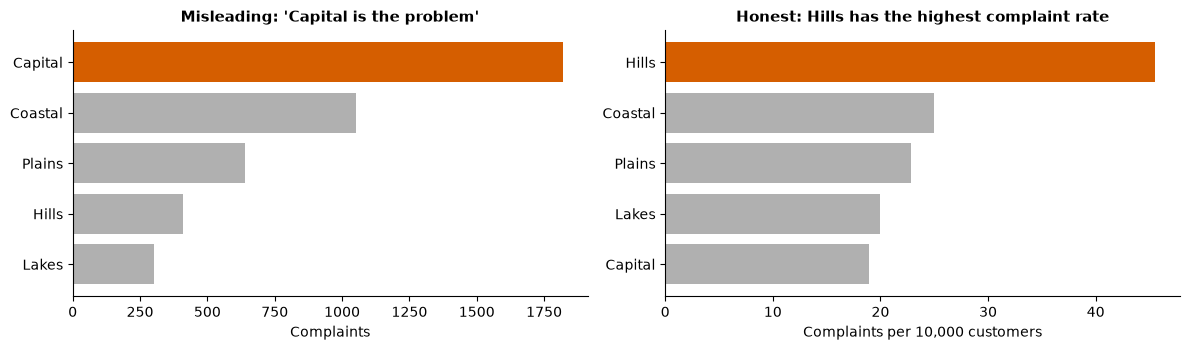

In [19]:
reg = pd.DataFrame({"region": ["Coastal", "Capital", "Hills", "Lakes", "Plains"],
                    "customers": [420_000, 960_000, 90_000, 150_000, 280_000],
                    "complaints": [1_050, 1_820, 410, 300, 640]})
reg["per_10k"] = 10_000 * reg["complaints"] / reg["customers"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
t = reg.sort_values("complaints")
axes[0].barh(t["region"], t["complaints"], color=GREY)
axes[0].barh(t["region"].iloc[-1], t["complaints"].iloc[-1], color=OI["vermillion"])
axes[0].set_title("Misleading: 'Capital is the problem'")
axes[0].set_xlabel("Complaints")
r = reg.sort_values("per_10k")
axes[1].barh(r["region"], r["per_10k"], color=GREY)
axes[1].barh(r["region"].iloc[-1], r["per_10k"].iloc[-1], color=OI["vermillion"])
axes[1].set_title("Honest: Hills has the highest complaint rate")
axes[1].set_xlabel("Complaints per 10,000 customers")
plt.tight_layout()
plt.show()

Big regions have more of everything. A chart (or a filled map) of raw totals is often just a chart of size. Divide by the right base: customers, orders, population, visits. This matters for every **filled map** you build in Tableau.

### 6. A cumulative line that hides a decline

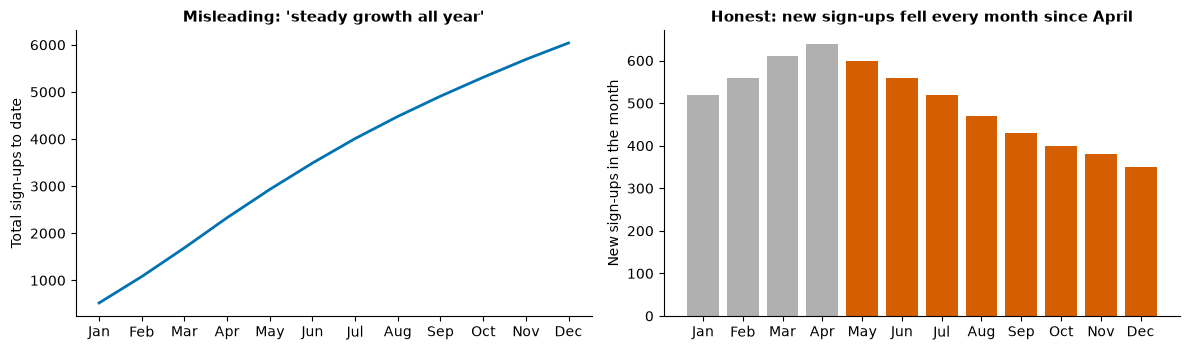

In [20]:
new_signups = np.array([520, 560, 610, 640, 600, 560, 520, 470, 430, 400, 380, 350])
m = pd.period_range("2025-01", periods=12, freq="M").strftime("%b")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(m, new_signups.cumsum(), color=OI["blue"], lw=2)
axes[0].set_title("Misleading: 'steady growth all year'")
axes[0].set_ylabel("Total sign-ups to date")
axes[1].bar(m, new_signups, color=[GREY] * 4 + [OI["vermillion"]] * 8)
axes[1].set_title("Honest: new sign-ups fell every month since April")
axes[1].set_ylabel("New sign-ups in the month")
plt.tight_layout()
plt.show()

A running total can only go up (as long as the monthly values are positive), so it disguises a slowdown. Show the **monthly flow** alongside, or instead.

### Five questions to ask any chart

1. **Where does each axis start,** and is the encoding length (needs zero) or position (does not)?
2. **Is there more than one scale,** and who chose it?
3. **Why this time window, this filter, these categories?** What was left out?
4. **Totals or rates?** Should the numbers be divided by something?
5. **Does the title claim more than the chart shows,** for example a cause where the chart shows only an association?

| Misconception | Better view |
|---|---|
| "Every y-axis must start at zero." | Bars must. Lines and dots may zoom in, but say so and do not exaggerate small noise. |
| "If the numbers are correct, the chart is honest." | Scale, window, base and title choices can mislead with correct numbers. |

---

## Part 5: Communicating results

### Exploratory and explanatory charts

So far today, most charts have been **explanatory**: built to show one finding to someone else. On Day 1 you made **exploratory** charts: many quick views to find out what is in the data. Both are necessary, but they are different products. The common failure in reports is to paste exploratory charts (defaults, every variable, no message) into a document meant for a decision maker.

### Start with the audience

Gordon's Chapter 5 starts communication from the **audience and the decision**, not from the software's default chart. Before you design anything, answer four questions:

| Question | Example answer |
|---|---|
| **Who** is the reader, and what do they already know? | A regional operations manager; knows the stores well, not statistics |
| **What decision** are they making, and when? | Whether to extend weekend opening hours, at Friday's meeting |
| **What do they believe now?** What might they push back on? | That weekends are quiet; they will ask whether last month was unusual |
| **What should they do or think after reading?** | Approve a three-month trial in two stores |

### The big idea

Cole Nussbaumer Knaflic (*Storytelling with Data*, 2015) suggests writing your **big idea** before making any slide: **one complete sentence** that states your point of view and **what is at stake**. If you cannot write it, you do not yet know what you are saying.

| Weak (a topic) | Strong (a big idea) |
|---|---|
| "Weekend sales analysis." | "Weekend afternoons now bring a third of our sales but get a fifth of our staff hours, so we are losing sales to queues; a trial of two extra staff in two stores would test the fix at low cost." |
| "Customer survey results." | "Delivery speed, not price, is what our lapsed customers complain about most, so the planned discount campaign is unlikely to win them back." |

### Situation, complication, resolution

Barbara Minto's **pyramid principle** says: lead with the answer, then give the supporting arguments, then the detail. A short way to structure the opening of any report or presentation is **SCR**:

- **Situation:** what the reader already knows and agrees with. *"We open all stores 9:00–18:00 every day, with the same staff all week."*
- **Complication:** what has changed or what is wrong. *"Since spring, Saturday and Sunday afternoons bring far more customers than weekdays; queue times on those afternoons have doubled and abandoned baskets are rising."*
- **Resolution:** what you recommend, and the evidence for it. *"Move two staff shifts from Tuesday mornings to weekend afternoons in two pilot stores for three months, and measure queue time and sales."*

The order matters. A report written in the order the work was done (data, cleaning, methods, results, conclusion) makes a busy reader wait until the end for the only part they need. **Finding first, method later** (or in an appendix).

### Titles that say the message

| Topic title (what the chart is about) | Message title (what the chart shows) |
|---|---|
| "Sales by region, 2025" | "South was the only region whose sales fell in 2025" |
| "Monthly complaints" | "Complaints doubled after the courier changed in June" |
| "Conversion by channel" | "Email converts four times better than social, at a tenth of the cost" |

A message title must be **true to the chart** and **specific** (with a number where possible). If you are not sure enough to write the claim, the chart is not ready to present.

### Worked example: from an exploratory default to an explanatory chart

A delivery company changed its courier in the North region in week 23. Here are weekly complaints for four regions.

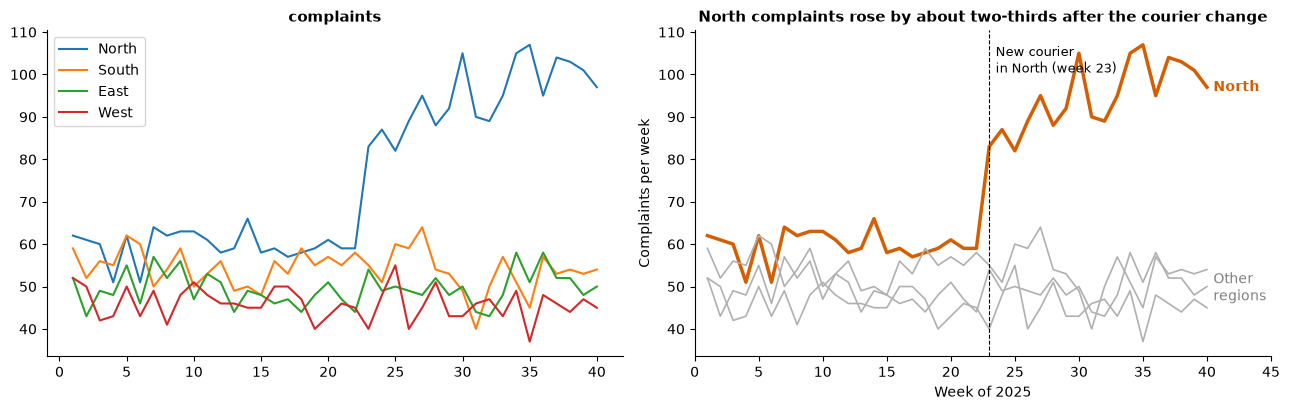

North, mean complaints per week: weeks 11-22 = 60, weeks 29-40 = 99, change = +66%


In [21]:
rng = np.random.default_rng(23)
weeks = np.arange(1, 41)
base = {"North": 60, "South": 55, "East": 50, "West": 45}
comp = pd.DataFrame({r: b + rng.normal(0, 4, len(weeks)) for r, b in base.items()}, index=weeks)
comp.loc[23:, "North"] += np.linspace(25, 45, len(weeks) - 22)
comp = comp.round()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
comp.plot(ax=axes[0])
axes[0].set_title("complaints")

ax = axes[1]
for r in comp.columns:
    ax.plot(comp.index, comp[r], color=OI["vermillion"] if r == "North" else GREY,
            lw=2.5 if r == "North" else 1.2)
ax.axvline(23, color="black", lw=0.8, ls="--")
ax.text(23.5, comp.values.max(), "New courier\nin North (week 23)", va="top", fontsize=9)
ax.text(40.5, comp["North"].iloc[-1], "North", color=OI["vermillion"], fontweight="bold", va="center")
ax.text(40.5, comp[["South", "East", "West"]].iloc[-1].mean(), "Other\nregions", color="grey", va="center")
ax.set_xlim(0, 45)
ax.set_xlabel("Week of 2025")
ax.set_ylabel("Complaints per week")
ax.set_title("North complaints rose by about two-thirds after the courier change")
plt.tight_layout()
plt.show()
before = comp.loc[11:22, "North"].mean(); after = comp.loc[29:40, "North"].mean()
print(f"North, mean complaints per week: weeks 11-22 = {before:.0f}, weeks 29-40 = {after:.0f}, change = {after / before - 1:+.0%}")

Five changes turned the left chart into the right one: (1) a **message title** with a number, checked by the printed calculation; (2) **one accent colour** for the series that matters and grey for context; (3) an **annotation** that marks the event and explains it; (4) **direct labels** instead of a legend; (5) **axis labels with units**. The data did not change.

Note the honest wording: the chart shows that complaints rose **after** the change. It does not prove the courier **caused** it (Day 1's confounding questions still apply: did anything else change in the North in week 23?). A good title claims exactly what the evidence supports.

### Writing numbers for a reader

- Always give **units**: "US$4.20 per order", "12 percentage points", "3.1 days".
- Give a **comparison**: versus last year, versus target, versus the other group. A number alone means little.
- **Round** to what the decision needs: "about 38%" rather than "37.846%".
- Distinguish **percent** from **percentage points**: a rate going from 10% to 12% is a rise of 2 percentage points, or 20%.
- State the **base and period**: "of 1,240 orders in March", "per 10,000 customers".

| Misconception | Better view |
|---|---|
| "Storytelling means making things up or dramatising." | It means ordering true evidence so the reader can follow it to a decision. |
| "Put every chart in, to show the work." | Put in the charts the argument needs; the rest go in an appendix. |
| "The title should be neutral." | It should be accurate. A specific, true message is more useful than a neutral label. |

---

## Part 6: KPIs and dashboards

### What makes a KPI

A **metric** is any number you can measure. A **key performance indicator (KPI)** is a metric chosen because it tracks progress towards an objective someone is responsible for. A useful KPI is:

- **Defined precisely:** numerator, denominator, period, filters, and who owns it ("orders delivered within 48 hours ÷ all orders delivered, per calendar week, excluding cancellations").
- **Tied to a decision or objective:** if it moves, someone knows what to do.
- **Compared with something:** a target, last period, or a benchmark.
- **Hard to game**, or paired with a balancing metric. Goodhart's law: when a measure becomes a target, it tends to stop being a good measure. Call-centre "average handling time" falls if agents hang up early; pair it with "issue resolved on first call".

**Leading** indicators move before the result (website visits, sales pipeline, staff training hours); **lagging** indicators record the result (revenue, churn). **Vanity metrics** look impressive but do not inform a decision (total app downloads since launch, page views without conversion).

### Ratio of sums or mean of ratios?

Many KPIs are ratios: conversion rate, profit margin, on-time rate. When you combine several units (stores, days, campaigns), there are two different ways to compute "the" rate, and they usually give different answers.

> **Predict, then run.** Six stores report visits and orders. Is the company's conversion rate above or below the average of the six stores' conversion rates?

In [22]:
stores = pd.DataFrame({"store": ["Airport", "Mall", "Station", "Harbour", "Campus", "Village"],
                       "visits": [12_000, 9_500, 7_000, 1_200, 800, 300],
                       "orders": [360, 380, 245, 66, 52, 27]})
stores["conversion"] = stores["orders"] / stores["visits"]
print(stores.assign(conversion=stores["conversion"].map("{:.1%}".format)).to_string(index=False))

mean_of_ratios = stores["conversion"].mean()
ratio_of_sums = stores["orders"].sum() / stores["visits"].sum()
print(f"\nMean of the six store rates (each store counts once):  {mean_of_ratios:.2%}")
print(f"Total orders / total visits (each visit counts once):  {ratio_of_sums:.2%}")

  store  visits  orders conversion
Airport   12000     360       3.0%
   Mall    9500     380       4.0%
Station    7000     245       3.5%
Harbour    1200      66       5.5%
 Campus     800      52       6.5%
Village     300      27       9.0%

Mean of the six store rates (each store counts once):  5.25%
Total orders / total visits (each visit counts once):  3.67%


The small stores convert better but have few visits. The **mean of ratios** gives each store equal weight, so the small stores pull it up; the **ratio of sums** gives each **visit** equal weight, so it reflects what the company actually achieved.

| You want | Use | Example |
|---|---|---|
| The rate the whole business achieved | **Ratio of sums**: Σ orders ÷ Σ visits | Company conversion rate; total profit ÷ total sales for the profit margin |
| How a **typical unit** performs | Mean (or median) of the unit ratios | "The typical store converts …" in a store league table |

In Tableau this is the difference between `SUM([Orders]) / SUM([Visits])` (ratio of sums) and `AVG([Orders] / [Visits])` (mean of row-level ratios). The Tableau lecture this afternoon returns to it. Always state which one a KPI uses.

### Anatomy of a KPI tile

A good KPI tile answers "how are we doing?" in two seconds: **name** and **period** ("On-time delivery, October"), the **value with its unit** (92.4%), a **comparison** (target 95%, −2.6 points; last month 93.1%), a small **trend** (a sparkline of the last 12 periods), and a **status** that does not rely on colour alone (an arrow or a "below target" label).

### Dashboard layout

A **dashboard** is a set of linked views on one screen that a specific audience uses to monitor or explore something repeatedly. Three kinds serve different readers:

| Kind | Reader | Typical content |
|---|---|---|
| Strategic | Executives | A few KPIs against targets, monthly or quarterly trends |
| Operational | Front-line managers | Today's or this week's numbers, alerts, drill-down to the item |
| Analytical | Analysts | Filters, many dimensions, exploration |

Layout principles:

1. **Purpose first.** One sentence: "This dashboard helps regional managers see whether their state is on track and which products cause losses."
2. **Reading order.** Readers of left-to-right languages start top-left, so put the most important KPIs there, overview first, detail lower down.
3. **Overview first, zoom and filter, then details on demand** (Shneiderman, 1996): the dashboard shows the whole; clicking filters it; tooltips give detail.
4. **Few views.** Three to five views fit a screen; more and each becomes too small to read.
5. **Consistency.** Same colour means the same thing everywhere; same number format; aligned edges on a grid.
6. **Make interactivity visible.** Say "Click a store to filter" in a subtitle; readers do not discover hidden features.

The next cell mocks up a small dashboard for a fictional coffee chain with matplotlib: three KPI tiles on top, a trend, and a sorted bar.

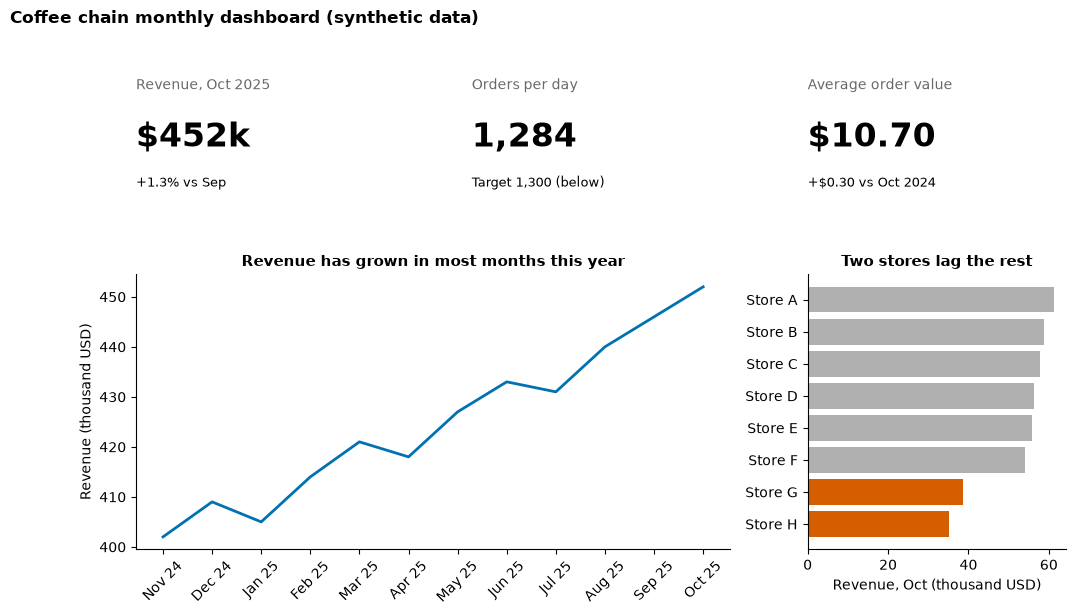

In [23]:
months = pd.period_range("2024-11", periods=12, freq="M")
revenue = np.array([402, 409, 405, 414, 421, 418, 427, 433, 431, 440, 446, 452.0])   # thousand USD
by_store = pd.Series([61.2, 58.7, 57.9, 56.4, 55.8, 54.1, 38.6, 35.2],
                     index=[f"Store {c}" for c in "ABCDEFGH"]).sort_values()

fig = plt.figure(figsize=(12, 6.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 2.4], hspace=0.45, wspace=0.3)
tiles = [("Revenue, Oct 2025", f"${revenue[-1]:.0f}k", f"{revenue[-1] / revenue[-2] - 1:+.1%} vs Sep"),
         ("Orders per day", "1,284", "Target 1,300 (below)"),
         ("Average order value", "$10.70", "+$0.30 vs Oct 2024")]
for i, (name, value, comp_text) in enumerate(tiles):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.text(0, 0.85, name, fontsize=10, color="dimgrey")
    ax.text(0, 0.35, value, fontsize=24, fontweight="bold")
    ax.text(0, 0.0, comp_text, fontsize=9)
ax = fig.add_subplot(gs[1, :2])
ax.plot(months.strftime("%b %y"), revenue, color=OI["blue"], lw=2)
ax.set_title("Revenue has grown in most months this year"); ax.set_ylabel("Revenue (thousand USD)")
ax.tick_params(axis="x", rotation=45)
ax = fig.add_subplot(gs[1, 2])
ax.barh(by_store.index, by_store.values, color=GREY)
ax.barh(by_store.index[:2], by_store.values[:2], color=OI["vermillion"])
ax.set_title("Two stores lag the rest"); ax.set_xlabel("Revenue, Oct (thousand USD)")
fig.suptitle("Coffee chain monthly dashboard (synthetic data)", x=0.02, ha="left", fontweight="bold")
plt.show()

| Misconception | Better view |
|---|---|
| "A dashboard should show everything we have." | It should answer the audience's recurring questions; everything else is a click or a report away. |
| "The more KPIs, the better informed." | Beyond a handful, nobody knows which ones matter. Choose, and pair each with a target. |
| "Averages of store rates are the company rate." | Only if every store has the same base. Otherwise use a ratio of sums. |

---

## Part 7: Marketing analytics

Gordon's Chapter 6 shows analytics supporting most marketing decisions: which **markets** to enter, understanding **customers**, setting **prices**, choosing **channels** (distribution), planning **promotion**, developing **products**, and **segmenting** customers. It also warns that analytics only scales when definitions are consistent across teams (**data governance**), and that careless use of customer data breaks trust and privacy rules. This part concentrates on the metrics a digital marketing team reports every week.

### The funnel

Customers move through stages, and at each stage some drop out. For an online campaign:

**impressions** (ad shown) → **clicks** → **visits** → **add to cart** → **orders**

| Metric | Formula | Question it answers |
|---|---|---|
| Click-through rate (**CTR**) | clicks ÷ impressions | Does the ad attract attention? |
| Cost per click (**CPC**) | spend ÷ clicks | What does attention cost? |
| Conversion rate (**CVR**) | orders ÷ clicks (or ÷ visits; say which) | Does the landing page and offer persuade? |
| Cost per acquisition (**CPA**) | spend ÷ orders (or ÷ new customers) | What does one sale or customer cost? |
| Return on ad spend (**ROAS**) | revenue ÷ spend | How much revenue per dollar of advertising? |
| Average order value (**AOV**) | revenue ÷ orders | How big is each sale? |

> **Predict, then run.** Four channels ran in one month. Which channel do you expect to have the best CTR, and will the same channel have the best ROAS?

In [24]:
camp = pd.DataFrame({
    "channel":     ["Search", "Social", "Email", "Display"],
    "impressions": [400_000, 1_500_000, 60_000, 2_500_000],
    "clicks":      [12_000, 60_000, 1_500, 7_500],
    "orders":      [540, 300, 120, 90],
    "spend":       [18_000, 15_000, 1_200, 6_000],     # US dollars
    "revenue":     [43_200, 19_500, 7_800, 6_300],     # US dollars
}).set_index("channel")

kpi = pd.DataFrame({
    "CTR": camp["clicks"] / camp["impressions"],
    "CPC ($)": camp["spend"] / camp["clicks"],
    "CVR": camp["orders"] / camp["clicks"],
    "CPA ($)": camp["spend"] / camp["orders"],
    "ROAS": camp["revenue"] / camp["spend"],
    "AOV ($)": camp["revenue"] / camp["orders"],
})
fmt = {"CTR": "{:.2%}", "CPC ($)": "{:.2f}", "CVR": "{:.1%}", "CPA ($)": "{:.2f}", "ROAS": "{:.2f}", "AOV ($)": "{:.2f}"}
print(kpi.apply(lambda col: col.map(fmt[col.name].format)).to_string())
total_roas = camp["revenue"].sum() / camp["spend"].sum()
print(f"\nAll channels: ROAS = {total_roas:.2f} (a ratio of sums, not the mean of the four ROAS values)")

           CTR CPC ($)   CVR CPA ($)  ROAS AOV ($)
channel                                           
Search   3.00%    1.50  4.5%   33.33  2.40   80.00
Social   4.00%    0.25  0.5%   50.00  1.30   65.00
Email    2.50%    0.80  8.0%   10.00  6.50   65.00
Display  0.30%    0.80  1.2%   66.67  1.05   70.00

All channels: ROAS = 1.91 (a ratio of sums, not the mean of the four ROAS values)


Each metric ranks the channels differently, which is exactly why a marketing report must say **which decision** a metric is for. Social wins attention (the best CTR and the cheapest clicks) but few of those clicks buy; Email is tiny but highly efficient; Search brings the most orders. Three cautions:

1. **ROAS uses revenue, not profit.** If the product margin is 40%, each dollar of revenue earns 40 cents before advertising, so the **break-even ROAS** is 1 ÷ 0.40 = 2.5. A ROAS of 2 looks positive and loses money; in this table even Search, at 2.4, is just below break-even on that margin.
2. **Efficient is not the same as scalable.** Email's numbers come from people who already know the brand, and the list is small; doubling email spend will not double its orders.
3. **Ratios hide volume.** Always show the counts (orders, spend) next to the rates.

The funnel chart below shows where Search loses people between stages.

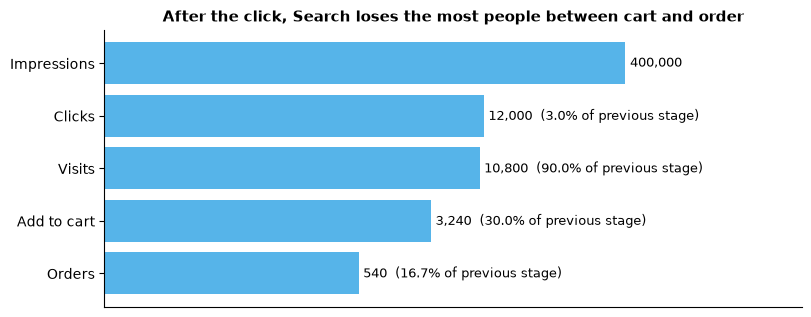

In [25]:
funnel = pd.Series({"Impressions": 400_000, "Clicks": 12_000, "Visits": 10_800,
                    "Add to cart": 3_240, "Orders": 540})
fig, ax = plt.subplots(figsize=(9, 3.6))
f = funnel.iloc[::-1]
ax.barh(f.index, np.log10(f.values), color=OI["sky"])
for y, (stage, v) in enumerate(f.items()):
    prev = funnel.shift(1).get(stage)
    step = "" if pd.isna(prev) else f"  ({v / prev:.1%} of previous stage)"
    ax.text(np.log10(v) + 0.05, y, f"{v:,}{step}", va="center", fontsize=9)
ax.set_xlim(0, 7.5); ax.set_xticks([])
ax.set_title("After the click, Search loses the most people between cart and order")
plt.show()

The bars use a **log scale** because the stages differ by a factor of almost a thousand; the labels carry the exact counts and the stage-to-stage rates, which are what a manager acts on. Of those rates, impressions to clicks is always small; among the later steps, cart to order is the weakest, which points to checkout (shipping costs, payment options) rather than to the ad.

### Customer lifetime value

**Customer lifetime value (CLV)** estimates the profit a customer brings over the whole relationship, so that you know how much it is worth spending to acquire one. A simple and widely used version assumes each customer brings margin *m* per year, stays each year with probability *r* (the retention rate), and future money is discounted at rate *d*:

**CLV = m × r ÷ (1 + d − r)**

This version counts margin from the end of the first year onwards (as Gupta and Lehmann, 2003, set it up); variants add the first year's margin. Compare CLV with the **customer acquisition cost (CAC)**; a common rule of thumb in subscription businesses is a CLV of at least three times CAC.

In [26]:
def clv(margin, retention, discount=0.10):
    return margin * retention / (1 + discount - retention)

for r in [0.60, 0.70, 0.80, 0.90]:
    print(f"margin $40/year, retention {r:.0%}: CLV = ${clv(40, r):,.0f}")

margin $40/year, retention 60%: CLV = $48
margin $40/year, retention 70%: CLV = $70
margin $40/year, retention 80%: CLV = $107
margin $40/year, retention 90%: CLV = $180


> **Predict, then run** (above). Raising retention from 80% to 90% adds more value than raising it from 60% to 70%. The formula is very sensitive to retention near the top, which is why subscription businesses spend so much on keeping customers. It is also sensitive to error: an estimate of 90% that is really 85% overstates CLV a lot. Report CLV with the assumptions next to it.

### Segmentation: RFM

**Segmentation** groups customers who behave similarly so that each group can be treated differently. A simple behavioural method is **RFM**: score each customer on **Recency** (days since last purchase; lower is better), **Frequency** (number of purchases) and **Monetary** value (total spend). Gordon's chapter also mentions **cluster analysis**, which finds groups from many variables at once; RFM is the transparent version a manager can check by hand.

In [27]:
rng = np.random.default_rng(42)
n = 2000
cust = pd.DataFrame({
    "recency_days": rng.gamma(2.0, 45, n).round() + 1,
    "frequency": rng.geometric(0.3, n),
})
cust["monetary"] = (cust["frequency"] * rng.gamma(2, 25, n)).round(2)   # US dollars

# Score 1-5 by quintile; recency is reversed (recent customers score 5)
cust["R"] = pd.qcut(cust["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
cust["F"] = pd.qcut(cust["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
cust["M"] = pd.qcut(cust["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(row):
    if row.R >= 4 and row.F >= 4: return "Champions"
    if row.R >= 4: return "Recent, not yet loyal"
    if row.R <= 2 and row.F >= 4: return "At risk (were loyal)"
    if row.R <= 2: return "Lapsed"
    return "Middle"

cust["segment"] = cust.apply(segment, axis=1)
summary = cust.groupby("segment").agg(customers=("monetary", "size"), revenue=("monetary", "sum"))
summary["share_customers"] = summary["customers"] / summary["customers"].sum()
summary["share_revenue"] = summary["revenue"] / summary["revenue"].sum()
summary = summary.sort_values("share_revenue", ascending=False)
print(summary[["customers", "share_customers", "share_revenue"]].to_string(
    formatters={"share_customers": "{:.0%}".format, "share_revenue": "{:.0%}".format}))

                       customers share_customers share_revenue
segment                                                       
Champions                    309             15%           29%
At risk (were loyal)         318             16%           26%
Middle                       400             20%           21%
Recent, not yet loyal        491             25%           12%
Lapsed                       482             24%           11%


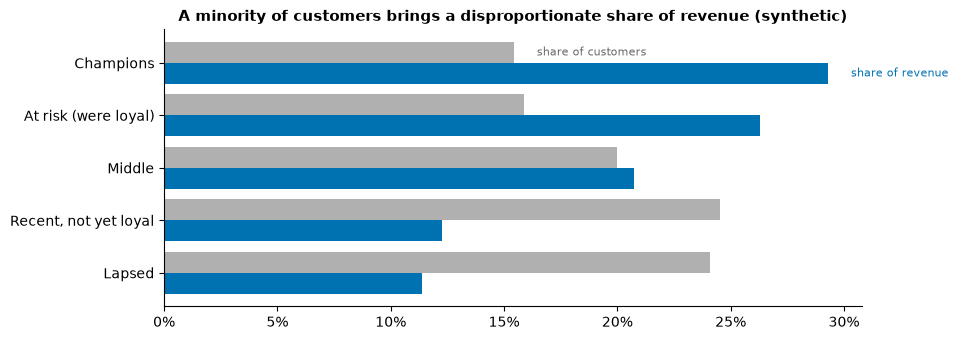

In [28]:
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(summary))
ax.barh(y - 0.2, summary["share_customers"], height=0.4, color=GREY)
ax.barh(y + 0.2, summary["share_revenue"], height=0.4, color=OI["blue"])
ax.set_yticks(y, summary.index); ax.invert_yaxis()
ax.text(summary["share_customers"].iloc[0] + 0.01, -0.2, "share of customers", va="center", fontsize=8, color="dimgrey")
ax.text(summary["share_revenue"].iloc[0] + 0.01, 0.2, "share of revenue", va="center", fontsize=8, color=OI["blue"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("A minority of customers brings a disproportionate share of revenue (synthetic)")
plt.show()

Each segment suggests a different action: thank and retain the Champions, win back those At risk before they lapse, nurture the Recent ones towards a second purchase. The segment rules are **choices**; write them down so others can reproduce them.

### Attribution and its limits

A customer may see a social ad, later click a search ad, then buy from an email. Which channel "gets" the sale? **Attribution models** divide the credit by rule:

In [29]:
journeys = [   # (channels touched, in order), number of orders that followed that journey
    (("Social", "Search", "Email"), 120),
    (("Search",), 200),
    (("Social", "Email"), 80),
    (("Display", "Search"), 60),
    (("Email",), 90),
    (("Display", "Social", "Search"), 50),
]

credit = {m: pd.Series(0.0, index=["Search", "Social", "Email", "Display"]) for m in ["Last click", "First click", "Linear"]}
for path, orders in journeys:
    credit["Last click"][path[-1]] += orders
    credit["First click"][path[0]] += orders
    for ch in path:
        credit["Linear"][ch] += orders / len(path)
print(pd.DataFrame(credit).round(0).astype(int).to_string())

         Last click  First click  Linear
Search          310          200     287
Social            0          200      97
Email           290           90     170
Display           0          110      47


The same 600 orders give very different channel "results" depending on the rule. Last click favours channels near the purchase (search, email); first click favours channels that introduce the brand (social, display). None of them is "true", because all of them answer a different question from the one the budget holder asks.

The deeper limit: attribution **divides credit among channels a buyer touched**; it does not tell you whether the sale would have happened **without** the ad (**incrementality**). Many people who click a search ad for the brand's own name were going to buy anyway. Tracking is also incomplete: privacy rules and browser and phone changes (such as Apple's App Tracking Transparency prompt, introduced in 2021) mean many journeys are only partly observed. The reliable way to measure incrementality is an **experiment**: show the ad to a random group and hold it back from a similar random control group.

### A quick A/B test

A shop shows the old checkout page to 5,000 random visitors (A) and a new one to another 5,000 (B).

In [30]:
nA, xA = 5_000, 200    # visitors and orders, old page
nB, xB = 5_000, 232    # visitors and orders, new page
pA, pB = xA / nA, xB / nB
se = np.sqrt(pA * (1 - pA) / nA + pB * (1 - pB) / nB)
diff = pB - pA
lo, hi = diff - 1.96 * se, diff + 1.96 * se
print(f"Conversion A = {pA:.2%}, B = {pB:.2%}, difference = {diff * 100:+.2f} percentage points")
print(f"Approximate 95% confidence interval for the difference: {lo * 100:+.2f} to {hi * 100:+.2f} points")

Conversion A = 4.00%, B = 4.64%, difference = +0.64 percentage points
Approximate 95% confidence interval for the difference: -0.16 to +1.44 points


> **Predict, then run** (above). B looks 16% better (4.64% against 4.00%). But the interval for the difference includes zero, so a test of this size cannot rule out that the new page makes no difference. Options: run the test longer, or decide in advance what difference is worth acting on and how many visitors are needed to detect it. The lesson for reports: **say how uncertain a difference is** before recommending on it.

| Misconception | Better view |
|---|---|
| "The channel with the best ROAS should get all the budget." | Returns usually fall as spend rises, and ROAS ignores margin and incrementality. Test increases in steps. |
| "Last-click attribution shows what works." | It shows who was last in line. Use experiments to measure what an ad adds. |
| "A higher conversion rate in a test proves the new version is better." | Only if the difference is larger than the noise; check the interval and the sample size. |
| "More customer data is always better." | Data you collect without a purpose, or without consent, creates privacy risk and erodes trust (Gordon, Ch. 6). |

---

## Part 8: Two real cases

### Case 1: John Snow and the Broad Street pump (London, 1854)

In late August 1854 cholera killed hundreds of people within a few streets of Soho in London. The accepted theory was that cholera spread through bad air ("miasma"). The physician John Snow suspected contaminated water. He collected the addresses of the dead, interviewed families, and found that most deaths clustered around the public water pump on Broad Street, while groups who drank from other sources (workers at a brewery with its own well, residents of a workhouse with its own pump) were largely spared. He persuaded the local board to remove the pump's handle on 8 September. His famous dot map of deaths around the pump was published the following year, in the second edition of his book on cholera.

Discussion questions:

1. What made Snow's evidence persuasive? Separate the **map** (position of each death) from the **comparisons** (brewery workers, the workhouse, people who walked to Broad Street from further away). Which were stronger evidence, and why?
2. Historians note the outbreak was already declining when the handle was removed. What does that mean for the claim "removing the handle ended the outbreak"? Write a message title for Snow's map that claims exactly what the evidence supports.
3. Snow's map shows **counts of deaths**, not a rate. When would a map of counts mislead (Part 4, example 5)? Why was it reasonable here?
4. The board acted before the map existed. What, then, was the map **for**? Who was its audience?

### Case 2: predicting customers' life events (Target, United States)

In 2012 a widely read *New York Times Magazine* article by Charles Duhigg described how the US retailer Target built a model that used changes in shopping baskets (for example, unscented lotion and certain supplements) to estimate which customers were likely to be pregnant, so it could send baby-product offers before competitors did. The article reported that customers found such targeted offers unsettling, and that the company began mixing baby offers in with unrelated products so the targeting was less obvious. Some details of the most-quoted anecdote in the article have been questioned since, but the case is widely used to discuss marketing analytics and privacy.

Discussion questions:

1. Which marketing decisions from Gordon's Chapter 6 does this model support (segmentation, promotion, timing)? What metric would the marketing team use to judge it?
2. The model could be **accurate** and still harm the business. How? Which stakeholders are affected, and what would you measure besides sales?
3. Disguising targeted offers among unrelated ones hides the targeting rather than removing it. Is that an acceptable response? What would a more transparent approach look like?
4. Write the big idea, in one sentence, for a memo **against** launching such a model at a company you know.

> **Sources for the cases.** Snow, J. (1855). *On the mode of communication of cholera* (2nd ed.). London: John Churchill. Duhigg, C. (2012, February 16). How companies learn your secrets. *The New York Times Magazine*.

---

## Part 9: Practice, quiz and summary

### Practice

#### Core

**Core 1.** For each question, name the chart form and one alternative: (a) Which of 15 product lines had the most returns last quarter? (b) Has the average delivery time changed over the last 24 months? (c) How are order values distributed, and are there unusual orders? (d) Do customers who wait longer give lower ratings?

**Core 2.** Using `penguins`, draw a sorted horizontal bar chart of the median bill length by species, with direct labels in millimetres and a message title.

**Core 3.** Using the `camp` table from Part 7, compute the CTR, CVR and ROAS for all four channels **combined**, using ratios of sums. Then compute the mean of the four channels' ROAS values. Explain in one sentence why they differ.

#### Stretch

**Stretch 1.** Rebuild the left-hand chart of the data-ink example so that **East** is the story. Write a message title that is true to the numbers.

**Stretch 2.** Write an SCR opening (three sentences) for the coffee-chain dashboard in Part 6, aimed at the operations director.

**Stretch 3.** In the A/B test, how many orders would page B need, out of 5,000 visitors, for the interval for the difference to exclude zero? Find it by trying values in the code.

#### Challenge

**Challenge 1.** Using `cars`, build a three-panel "dashboard" with matplotlib (a KPI row with the number of models and the median mpg, a line of median mpg by model year, and a sorted bar of model counts by origin). Apply every rule from Part 6. Do not fit any regression lines.

**Challenge 2.** Write a function `check_palette(hex_list)` that shows a palette next to its simulated deuteranopia version, using `simulate_deutan`. Test Tableau's default categorical palette colours (`#4E79A7, #F28E2B, #E15759, #76B7B2, #59A14F`) and say which pairs become hard to tell apart.

**Challenge 3.** Add a "time decay" attribution model to the journeys example, giving each touch twice the credit of the touch before it. Compare it with the other three models.

### Quiz

1. Name the chart form for each question shape: rank, change over time, distribution, relationship, deviation from target.
2. Rank these encodings from most to least accurately read: area, position on a common scale, colour hue, length.
3. Why must bars start at zero when lines need not?
4. Give two pre-attentive attributes and explain why one highlight colour against grey works better than five colours.
5. Which Gestalt principle are you using when you shade a promotion period on a line chart?
6. What kind of palette suits profit, and where must its midpoint be?
7. Name three ways a chart built from correct numbers can mislead.
8. Write a message title for a chart showing monthly returns falling from 9% to 6% after a new size guide launched in May.
9. Six stores' conversion rates average 5.8%, but the company rate is 3.7%. How is that possible, and which number should the CEO see?
10. A channel has a ROAS of 2.2 and the product margin is 35%. Is the channel profitable before other costs? Show the calculation.
11. What question does attribution answer, and what question does it not answer?

### Summary

| Idea | Remember |
|---|---|
| Chart choice | Start from the question's shape: rank, time, distribution, relationship, part-to-whole, deviation, geography, flow |
| Perception | Position and length are read best; angle, area and colour worse. Put the key comparison on the best channel |
| Attention | One accent colour against grey; group with proximity, similarity, enclosure, connection |
| Data-ink | Remove borders, heavy grids, legends you can replace with labels, and false precision |
| Colour | Sequential, diverging (centred), categorical; colour-blind safe; never colour alone |
| Honesty | Zero for bars; one scale; enough history; rates not totals; flows not only cumulatives; claim only what is shown |
| Communication | Audience and decision first; a one-sentence big idea; SCR; finding first; message titles; annotate |
| KPIs | Defined, owned, compared with a target; ratio of sums for the business rate |
| Dashboards | Purpose, top-left priority, overview then detail, three to five views, consistent, visible interactivity |
| Marketing | CTR, CPC, CVR, CPA, ROAS (break-even = 1 ÷ margin), CLV versus CAC, segmentation; attribution is not incrementality |

**References:** Cleveland, W. S., & McGill, R. (1984). Graphical perception. *Journal of the American Statistical Association*, 79(387), 531–554. Tufte, E. R. (1983). *The visual display of quantitative information*. Graphics Press. Knaflic, C. N. (2015). *Storytelling with data*. Wiley. Minto, B. (1987). *The pyramid principle*. Pitman. Shneiderman, B. (1996). The eyes have it. *Proceedings of the IEEE Symposium on Visual Languages*, 336–343. Machado, G. M., Oliveira, M. M., & Fernandes, L. A. F. (2009). A physiologically-based model for simulation of color vision deficiency. *IEEE Transactions on Visualization and Computer Graphics*, 15(6), 1291–1298. Okabe, M., & Ito, K. (2008). *Color universal design*. Gupta, S., & Lehmann, D. R. (2003). Customers as assets. *Journal of Interactive Marketing*, 17(1), 9–24. Gordon, M. E. (2023). *Business analytics*, Chapters 5 and 6. SAGE.

**Next:** [Tableau concepts and dashboards](D2_lecture_tableau_dashboards.md), then the [Lab 2 guide](guides/lab2_dashboard.md) and the [Assignment 1 guide](guides/assignment1_descriptive_report.md).

---

## For the facilitator

This notebook fills periods P1–P4 of Day 2. The Tableau lecture follows in P5–P6, Lab 2 in P7–P8, and Assignment 1 in P9–P10. No graded answers are given here: no Superstore and no tips data are used.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P1 | 10 | Part 1: the question-shape table | Ask students to turn three vague requests into questions with a question mark |
| P1 | 25 | Part 1: examples 1–6 | Take the pie prediction by show of hands before revealing the bar chart |
| P1 | 10 | Part 2: encodings and the A-to-B estimate | Collect estimates on the board; compare length with area |
| P2 | 10 | Part 2: pre-attentive attributes, Gestalt, data-ink | Time the "find the odd point" panels with a volunteer |
| P2 | 10 | Part 3: palettes, rainbow, colour vision deficiency | Ask whether anyone is willing to say which palette they can read; never single anyone out |
| P2 | 25 | Part 4: the six misleading charts | Show the left chart first, ask "what would you conclude?", then the rebuild |
| P3 | 25 | Part 5: audience, big idea, SCR, message titles, the courier example | Pairs write a big idea for the courier chart in two minutes |
| P3 | 20 | Part 6: KPIs, ratio of sums, KPI tiles, dashboard layout | Take the store prediction vote; link to tonight's Tableau `SUM/SUM` |
| P4 | 30 | Part 7: funnel, metrics, break-even ROAS, CLV, RFM, attribution, A/B test | Have students compute CTR and CPA for one channel by hand first |
| P4 | 15 | Part 8: the two cases | Small groups, one question each, report back one sentence |

Practice and quiz are for the evening study block or for faster groups. Do not open Superstore or the tips data in these periods.